Praktikum 3 - Exact NN (sklearn brute) vs HNSW.

hnswlib tidak bisa di-build di mesin ini (tidak ada MSVC), jadi HNSW memakai
faiss.IndexHNSWFlat dengan parameter setara: M=16, efConstruction=100, efSearch=50.
Variasi: metrik L2 vs IP (cosine), 1.000 vs 1.000.000 data, 2D vs 5D.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p3_hnsw.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-3


In [2]:
from pathlib import Path
import csv
import time

import numpy as np
import faiss
import matplotlib
from sklearn.neighbors import NearestNeighbors

import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
K = 5

In [3]:
def unit(A):
    return A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)

L2 N=   1000 d=2 | exact [258  17 971 187 794] [0.0057 0.0099 0.0322 0.0334 0.0361] | hnsw [258  17 971 187 794] [0.     0.0001 0.001  0.0011 0.0013] | 4.581 ms vs 0.018 ms (build 52 ms) recall=1.000
L2 N=   1000 d=5 | exact [812  34 550 962 251] [0.1773 0.1992 0.2345 0.2693 0.273 ] | hnsw [812  34 550 962 251] [0.0314 0.0397 0.055  0.0725 0.0745] | 0.157 ms vs 0.011 ms (build 61 ms) recall=1.000


L2 N=1000000 d=2 | exact [600900 695075 587490 751043 109689] [0.0006 0.0008 0.0009 0.0011 0.0014] | hnsw [600900 695075 587490 751043 109689] [0. 0. 0. 0. 0.] | 2.643 ms vs 0.070 ms (build 14491 ms) recall=1.000


L2 N=1000000 d=5 | exact [ 85158 586716 687018   8630  91763] [0.047  0.0509 0.0534 0.0592 0.06  ] | hnsw [ 85158 586716 687018   8630  91763] [0.0022 0.0026 0.0029 0.0035 0.0036] | 2.882 ms vs 0.031 ms (build 25644 ms) recall=1.000
IP N=   1000 d=2 | exact [241 527 622 947 597] [0.     0.     0.     0.     0.0001] | hnsw [241 527 622 947 597] [1.     1.     1.     1.     0.9999] | 0.195 ms vs 0.958 ms (build 45 ms) recall=1.000
IP N=   1000 d=5 | exact [138 356 209 599 595] [0.0388 0.0589 0.0615 0.0782 0.0862] | hnsw [138 356 209 599 595] [0.9612 0.9411 0.9385 0.9218 0.9138] | 0.156 ms vs 0.011 ms (build 62 ms) recall=1.000


IP N=1000000 d=2 | exact [996033 366625 298044 412031 739699] [0. 0. 0. 0. 0.] | hnsw [917558 846648 843667 412031  41984] [1. 1. 1. 1. 1.] | 14.623 ms vs 0.021 ms (build 18704 ms) recall=0.060


IP N=1000000 d=5 | exact [901365 779224 732589 766000 586977] [0.0013 0.0015 0.0021 0.0022 0.0023] | hnsw [901365 779224 732589 766000 586977] [0.9987 0.9985 0.9979 0.9978 0.9977] | 16.041 ms vs 0.020 ms (build 24739 ms) recall=1.000


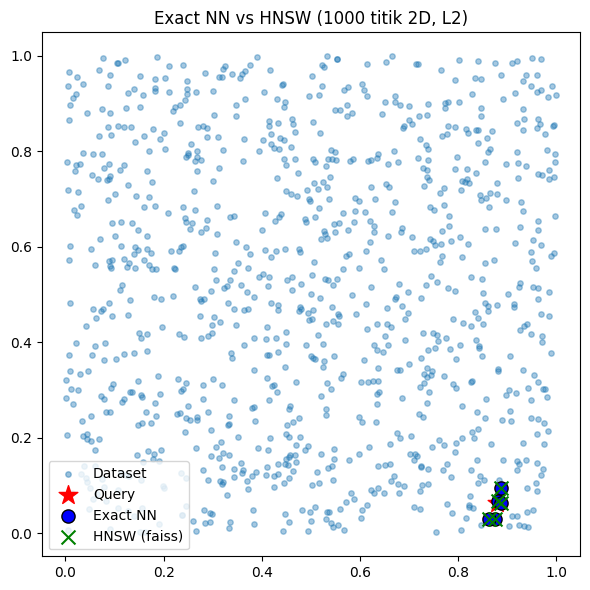

In [4]:
def run(n, d, metric, M=16, efc=100, ef=50):
    rng = np.random.default_rng(42)
    if metric == "ip":
        X = unit(rng.standard_normal((n, d), dtype=np.float32))
        Q = unit(rng.standard_normal((20, d), dtype=np.float32))
        mf, sk = faiss.METRIC_INNER_PRODUCT, "cosine"
    else:
        X = rng.random((n, d), dtype=np.float32)
        Q = rng.random((20, d), dtype=np.float32)
        mf, sk = faiss.METRIC_L2, "euclidean"

    nn = NearestNeighbors(n_neighbors=K, algorithm="brute", metric=sk).fit(X)
    t0 = time.perf_counter()
    D_e, I_e = nn.kneighbors(Q)
    t_e = (time.perf_counter() - t0) / len(Q) * 1000

    t0 = time.perf_counter()
    idx = faiss.IndexHNSWFlat(d, M, mf)
    idx.hnsw.efConstruction = efc
    idx.add(X)
    build = (time.perf_counter() - t0) * 1000
    idx.hnsw.efSearch = ef
    t0 = time.perf_counter()
    D_a, I_a = idx.search(Q, K)
    t_a = (time.perf_counter() - t0) / len(Q) * 1000

    rec = float(np.mean([len(set(a) & set(b)) / K for a, b in zip(I_a, I_e)]))
    return dict(I_e=I_e, D_e=D_e, I_a=I_a, D_a=D_a, t_e=t_e, t_a=t_a, build=build,
                rec=rec, X=X, Q=Q)


rows, plot_case = [], None
for metric in ["l2", "ip"]:
    for n in [1000, 1_000_000]:
        for d in [2, 5]:
            r = run(n, d, metric)
            rows.append([metric, n, d, r["t_e"], r["build"], r["t_a"],
                         round(r["t_e"] / r["t_a"], 2), round(r["rec"], 3)])
            print(f"{metric.upper():2s} N={n:7d} d={d} | exact {r['I_e'][0]} {np.round(r['D_e'][0], 4)} "
                  f"| hnsw {r['I_a'][0]} {np.round(r['D_a'][0], 4)} "
                  f"| {r['t_e']:.3f} ms vs {r['t_a']:.3f} ms (build {r['build']:.0f} ms) recall={r['rec']:.3f}")
            if n == 1000 and d == 2 and metric == "l2":
                plot_case = r

with open(OUT / "hasil_tabel.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metrik", "jumlah_data", "dimensi", "exact_ms", "build_ms", "hnsw_ms", "speedup", "recall@5"])
    w.writerows(rows)

r = plot_case
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(r["X"][:, 0], r["X"][:, 1], alpha=0.4, s=15, label="Dataset")
ax.scatter(*r["Q"][0], c="red", marker="*", s=200, label="Query")
ax.scatter(*r["X"][r["I_e"][0]].T, c="blue", s=90, edgecolor="k", label="Exact NN")
ax.scatter(*r["X"][r["I_a"][0]].T, c="green", marker="x", s=100, label="HNSW (faiss)")
ax.legend()
ax.set_title("Exact NN vs HNSW (1000 titik 2D, L2)")
fig.tight_layout()
fig.savefig(OUT / "p3_exact_vs_hnsw.png", dpi=120)